# ML Assignment 2: Obesity Level Classification

### NAME - Atharva Sadanand Litake
### BITS ID - 2026AJ05822

**Objective**: Train and compare five classification models that predict a person's obesity category from lifestyle, eating-habit, and physical-condition attributes.

**Dataset**: UCI *Estimation of Obesity Levels Based on Eating Habits and Physical Condition* (id 544) - 2,111 instances, 16 features, 7-class target `NObeyesdad`.

**Models compared**: Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes, Support Vector Machine.

**Evaluation metrics**: Accuracy, AUC (macro, one-vs-rest), Precision (macro), Recall (macro), F1 (macro), Matthews Correlation Coefficient.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, classification_report, confusion_matrix
)

sns.set_style('darkgrid')

def print_section(title, width=70):
    """Print a bordered header for consistent console output."""
    print('=' * width)
    print(title)
    print('=' * width)

---
## Data Loading

The dataset is fetched directly from the UCI ML Repository (id 544) via the `ucimlrepo` package, so the notebook does not depend on a locally-staged copy.

In [2]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=544)
X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets.copy()

TARGET_COL = y_raw.columns[0]
raw_df = pd.concat([X_raw, y_raw], axis=1)

# Persist the raw dataset so the repo is reproducible without a network call.
raw_df.to_csv('../data/obesity_raw.csv', index=False)

print_section('DATASET LOADED')
print(f"Shape : {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
print(f"Target column : {TARGET_COL}")
print('-' * 70)
print('Feature dtypes:')
print(raw_df.dtypes)
print('-' * 70)
print(f"Total missing values : {raw_df.isnull().sum().sum()}")

DATASET LOADED
Shape : 2111 rows x 17 columns
Target column : NObeyesdad
----------------------------------------------------------------------
Feature dtypes:
Gender                                str
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight        str
FAVC                                  str
FCVC                              float64
NCP                               float64
CAEC                                  str
SMOKE                                 str
CH2O                              float64
SCC                                   str
FAF                               float64
TUE                               float64
CALC                                  str
MTRANS                                str
NObeyesdad                            str
dtype: object
----------------------------------------------------------------------
Total missing values : 0


### Q1. Dataset overview and class balance

TARGET CLASS DISTRIBUTION
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64
----------------------------------------------------------------------
Number of classes : 7


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,2111,2,Male,1068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,2111.0,NaN,NaN,NaN,24.3126,6.345968,14.0,19.947192,22.77789,26.0,61.0
Height,2111.0,NaN,NaN,NaN,1.701677,0.093305,1.45,1.63,1.700499,1.768464,1.98
Weight,2111.0,NaN,NaN,NaN,86.586058,26.191172,39.0,65.473343,83.0,107.430682,173.0
family_history_with_overweight,2111,2,yes,1726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FAVC,2111,2,yes,1866,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FCVC,2111.0,NaN,NaN,NaN,2.419043,0.533927,1.0,2.0,2.385502,3.0,3.0
NCP,2111.0,NaN,NaN,NaN,2.685628,0.778039,1.0,2.658738,3.0,3.0,4.0
CAEC,2111,4,Sometimes,1765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SMOKE,2111,2,no,2067,NaN,NaN,NaN,NaN,NaN,NaN,NaN


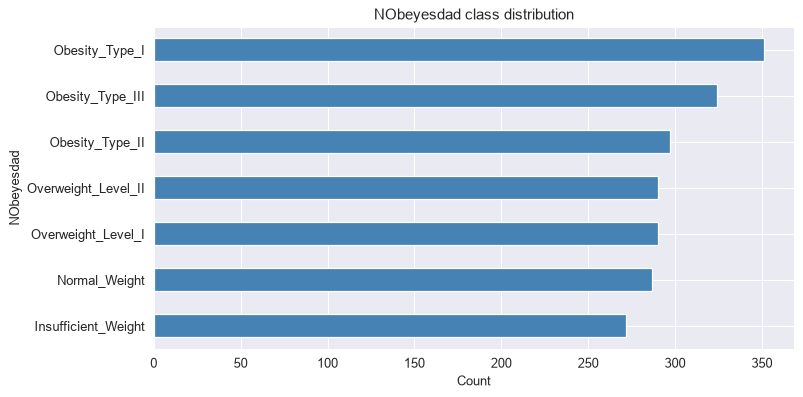

In [3]:
print_section('TARGET CLASS DISTRIBUTION')
class_counts = raw_df[TARGET_COL].value_counts()
print(class_counts)
print('-' * 70)
print(f"Number of classes : {raw_df[TARGET_COL].nunique()}")

plt.figure(figsize=(9, 4.5))
class_counts.sort_values().plot(kind='barh', color='steelblue')
plt.xlabel('Count')
plt.title('NObeyesdad class distribution')
plt.tight_layout()
plt.show()

raw_df.describe(include='all').transpose()

**Answer Q1:**

- The dataset has **2,111 rows** and **17 columns** (16 features + the `NObeyesdad` target), with **no missing values**.
- The 7 target classes are reasonably close in size (roughly 13-16% of rows each), so no heavy class-imbalance handling (e.g. SMOTE) is required - stratified splitting is enough.
- Features split into three groups: continuous physical measurements (`Age`, `Height`, `Weight`), ordinal-ish lifestyle scores stored as floats (`FCVC`, `NCP`, `CH2O`, `FAF`, `TUE`), and categorical/binary lifestyle attributes (`Gender`, `family_history_with_overweight`, `FAVC`, `CAEC`, `SMOKE`, `SCC`, `CALC`, `MTRANS`).

### Q2. Relationships between key features and the target

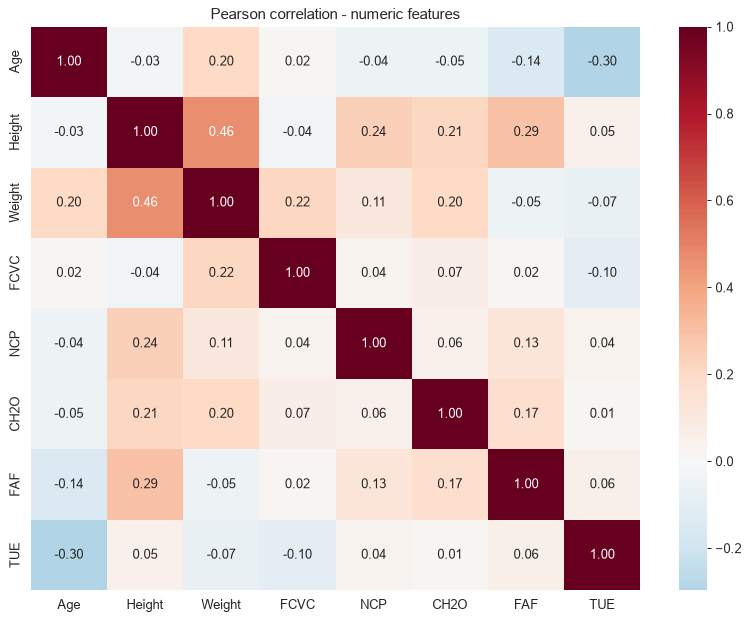

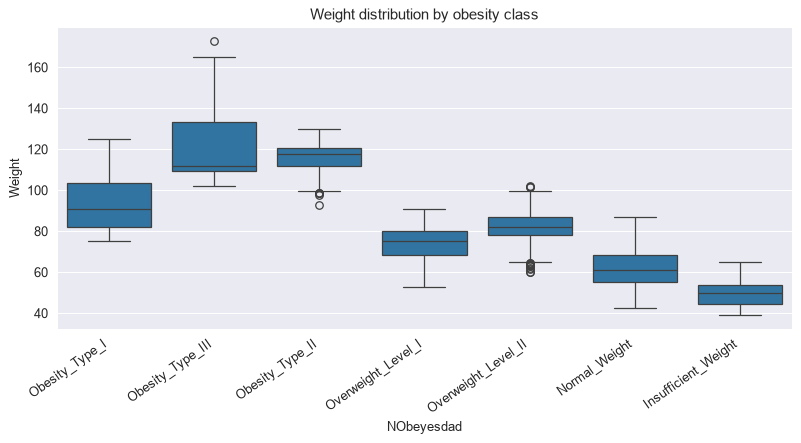

In [4]:
numeric_cols_preview = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

plt.figure(figsize=(9, 7))
sns.heatmap(raw_df[numeric_cols_preview].corr(), annot=True, cmap='RdBu_r', fmt='.2f', center=0)
plt.title('Pearson correlation - numeric features')
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=raw_df, x=TARGET_COL, y='Weight', order=class_counts.index)
plt.xticks(rotation=35, ha='right')
plt.title('Weight distribution by obesity class')
plt.tight_layout()
plt.show()

**Answer Q2:**

- `Weight` separates the target classes almost monotonically (Insufficient_Weight lowest, Obesity_Type_III highest), as expected since obesity categories are themselves derived from BMI = Weight / Height^2.
- `Height` and `Age` correlate weakly with the other numeric features, so most of the discriminative signal for the lower-weight classes will have to come from the lifestyle/categorical columns (diet, physical activity, transport mode) rather than physical measurements alone.
- None of the numeric features are strongly collinear with each other (|r| < 0.4 everywhere off-diagonal), so no features need to be dropped before modeling.

---
## Train/Test Split

The split is taken on the **raw**, unencoded dataframe and stratified on the target so every class keeps its proportion in both halves. The held-out 20% is written to `test_data.csv` in its original (human-readable) form - this is both the "test data used in your experiments" repo requirement and the exact file the Streamlit app expects to be uploaded, since the saved pipelines include their own preprocessing and can score raw rows directly.

In [5]:
FEATURE_COLS = [c for c in raw_df.columns if c != TARGET_COL]

train_df, test_df = train_test_split(
    raw_df, test_size=0.2, random_state=42, stratify=raw_df[TARGET_COL]
)

test_df.to_csv('../test_data.csv', index=False)

print_section('TRAIN / TEST SPLIT')
print(f"Train : {train_df.shape[0]} rows")
print(f"Test  : {test_df.shape[0]} rows  (saved to test_data.csv)")
print('-' * 70)
print('Test-set class balance:')
print(test_df[TARGET_COL].value_counts(normalize=True).round(3))

TRAIN / TEST SPLIT
Train : 1688 rows
Test  : 423 rows  (saved to test_data.csv)
----------------------------------------------------------------------
Test-set class balance:
NObeyesdad
Obesity_Type_I         0.165
Obesity_Type_III       0.154
Obesity_Type_II        0.142
Normal_Weight          0.137
Overweight_Level_II    0.137
Overweight_Level_I     0.137
Insufficient_Weight    0.128
Name: proportion, dtype: float64


---
## Preprocessing Pipeline

A single `ColumnTransformer` one-hot encodes the categorical/binary columns and standardizes the numeric columns. It is embedded inside every model's `Pipeline`, so cross-validation folds and the final saved artifacts all fit preprocessing only on their own training rows - no leakage from the held-out test split.

In [6]:
NUMERIC_COLS = [c for c in FEATURE_COLS if pd.api.types.is_numeric_dtype(raw_df[c])]
CATEGORICAL_COLS = [c for c in FEATURE_COLS if c not in NUMERIC_COLS]

print_section('FEATURE GROUPS')
print(f"Categorical ({len(CATEGORICAL_COLS)}): {CATEGORICAL_COLS}")
print(f"Numeric ({len(NUMERIC_COLS)}): {NUMERIC_COLS}")

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL_COLS),
    ('num', StandardScaler(), NUMERIC_COLS),
])

label_encoder = LabelEncoder()
label_encoder.fit(raw_df[TARGET_COL])

X_train, y_train = train_df[FEATURE_COLS], label_encoder.transform(train_df[TARGET_COL])
X_test, y_test = test_df[FEATURE_COLS], label_encoder.transform(test_df[TARGET_COL])
N_CLASSES = len(label_encoder.classes_)

print('-' * 70)
print(f"Classes ({N_CLASSES}): {label_encoder.classes_.tolist()}")

FEATURE GROUPS
Categorical (8): ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']
Numeric (8): ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
----------------------------------------------------------------------
Classes (7): ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']


In [7]:
def evaluate_model(name, pipeline, X_eval, y_eval):
    """Compute the six required metrics for a fitted pipeline on a held-out split."""
    y_pred = pipeline.predict(X_eval)
    y_proba = pipeline.predict_proba(X_eval)
    auc = roc_auc_score(y_eval, y_proba, multi_class='ovr', average='macro')
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_eval, y_pred),
        'AUC': auc,
        'Precision': precision_score(y_eval, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_eval, y_pred, average='macro', zero_division=0),
        'F1': f1_score(y_eval, y_pred, average='macro', zero_division=0),
        'MCC': matthews_corrcoef(y_eval, y_pred),
    }

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
fitted_pipelines = {}

---
## Model 1: Logistic Regression

Multinomial logistic regression, tuned over the inverse-regularization strength `C` with 5-fold stratified CV (scoring on macro F1, since classes are only mildly imbalanced but still worth weighting equally).

In [8]:
lr_pipeline = Pipeline([('prep', preprocessor), ('model', LogisticRegression(max_iter=2000, random_state=42))])
lr_search = GridSearchCV(lr_pipeline, {'model__C': [0.01, 0.1, 1, 10, 100]}, cv=CV, scoring='f1_macro', n_jobs=-1)
lr_search.fit(X_train, y_train)

fitted_pipelines['logistic_regression'] = lr_search.best_estimator_
res = evaluate_model('Logistic Regression', lr_search.best_estimator_, X_test, y_test)
results.append(res)

print_section('LOGISTIC REGRESSION')
print(f"Best C : {lr_search.best_params_['model__C']}")
print('-' * 70)
for k, v in res.items():
    print(f"{k:>10}: {v if isinstance(v, str) else round(v, 4)}")

LOGISTIC REGRESSION
Best C : 100
----------------------------------------------------------------------
     Model: Logistic Regression
  Accuracy: 0.9598
       AUC: 0.9974
 Precision: 0.9588
    Recall: 0.9593
        F1: 0.959
       MCC: 0.9531


---
## Model 2: Decision Tree

Tuned over `max_depth` and `min_samples_leaf` to control overfitting on this relatively small (2,111-row) dataset.

In [9]:
dt_pipeline = Pipeline([('prep', preprocessor), ('model', DecisionTreeClassifier(random_state=42))])
dt_param_grid = {'model__max_depth': [3, 5, 7, 10, None], 'model__min_samples_leaf': [1, 2, 5]}
dt_search = GridSearchCV(dt_pipeline, dt_param_grid, cv=CV, scoring='f1_macro', n_jobs=-1)
dt_search.fit(X_train, y_train)

fitted_pipelines['decision_tree'] = dt_search.best_estimator_
res = evaluate_model('Decision Tree', dt_search.best_estimator_, X_test, y_test)
results.append(res)

print_section('DECISION TREE')
print(f"Best params : {dt_search.best_params_}")
print('-' * 70)
for k, v in res.items():
    print(f"{k:>10}: {v if isinstance(v, str) else round(v, 4)}")

DECISION TREE
Best params : {'model__max_depth': None, 'model__min_samples_leaf': 1}
----------------------------------------------------------------------
     Model: Decision Tree
  Accuracy: 0.9149
       AUC: 0.9488
 Precision: 0.9152
    Recall: 0.9117
        F1: 0.913
       MCC: 0.9007


---
## Model 3: K-Nearest Neighbors

`n_neighbors` is tuned over odd values from 3 to 21 to avoid tied votes. KNN is distance-based, so it relies entirely on the `StandardScaler` step inside the pipeline to keep `Weight`/`Height`/`Age` from dominating the smaller lifestyle-score features.

In [10]:
knn_pipeline = Pipeline([('prep', preprocessor), ('model', KNeighborsClassifier())])
knn_search = GridSearchCV(knn_pipeline, {'model__n_neighbors': list(range(3, 22, 2))}, cv=CV, scoring='f1_macro', n_jobs=-1)
knn_search.fit(X_train, y_train)

fitted_pipelines['knn'] = knn_search.best_estimator_
res = evaluate_model('KNN', knn_search.best_estimator_, X_test, y_test)
results.append(res)

print_section('K-NEAREST NEIGHBORS')
print(f"Best k : {knn_search.best_params_['model__n_neighbors']}")
print('-' * 70)
for k, v in res.items():
    print(f"{k:>10}: {v if isinstance(v, str) else round(v, 4)}")

K-NEAREST NEIGHBORS
Best k : 3
----------------------------------------------------------------------
     Model: KNN
  Accuracy: 0.8582
       AUC: 0.9577
 Precision: 0.8523
    Recall: 0.8528
        F1: 0.8459
       MCC: 0.8362


---
## Model 4: Gaussian Naive Bayes

No hyperparameters are tuned here - Gaussian NB's only real "knob" (`var_smoothing`) rarely moves performance much, and the brief does not require tuning every model, only training and evaluating them fairly.

In [11]:
nb_pipeline = Pipeline([('prep', preprocessor), ('model', GaussianNB())])
nb_pipeline.fit(X_train, y_train)

fitted_pipelines['naive_bayes'] = nb_pipeline
res = evaluate_model('Naive Bayes', nb_pipeline, X_test, y_test)
results.append(res)

print_section('GAUSSIAN NAIVE BAYES')
for k, v in res.items():
    print(f"{k:>10}: {v if isinstance(v, str) else round(v, 4)}")

GAUSSIAN NAIVE BAYES
     Model: Naive Bayes
  Accuracy: 0.5083
       AUC: 0.8372
 Precision: 0.5207
    Recall: 0.5002
        F1: 0.4511
       MCC: 0.4471


---
## Model 5: Support Vector Machine

An RBF-kernel SVM, tuned over `C` and `gamma`, with `probability=True` so a macro-averaged one-vs-rest AUC can be computed alongside the other models.

In [12]:
svm_pipeline = Pipeline([('prep', preprocessor), ('model', SVC(kernel='rbf', probability=True, random_state=42))])
svm_param_grid = {'model__C': [0.1, 1, 10, 100], 'model__gamma': ['scale', 'auto']}
svm_search = GridSearchCV(svm_pipeline, svm_param_grid, cv=CV, scoring='f1_macro', n_jobs=-1)
svm_search.fit(X_train, y_train)

fitted_pipelines['svm'] = svm_search.best_estimator_
res = evaluate_model('Support Vector Machine', svm_search.best_estimator_, X_test, y_test)
results.append(res)

print_section('SUPPORT VECTOR MACHINE')
print(f"Best params : {svm_search.best_params_}")
print('-' * 70)
for k, v in res.items():
    print(f"{k:>10}: {v if isinstance(v, str) else round(v, 4)}")

SUPPORT VECTOR MACHINE
Best params : {'model__C': 100, 'model__gamma': 'auto'}
----------------------------------------------------------------------
     Model: Support Vector Machine
  Accuracy: 0.9504
       AUC: 0.9986
 Precision: 0.95
    Recall: 0.9493
        F1: 0.9495
       MCC: 0.9421


---
## Model Comparison

In [13]:
results_df = pd.DataFrame(results)
for col in ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']:
    results_df[col] = results_df[col].round(4)
results_df = results_df.sort_values('F1', ascending=False).reset_index(drop=True)
results_df.insert(0, 'Rank', results_df.index + 1)

print_section('MODEL LEADERBOARD (sorted by F1)', width=100)
print(results_df.to_string(index=False))

best_row = results_df.iloc[0]
print('-' * 100)
print(f"Winner : {best_row['Model']}  |  F1 = {best_row['F1']:.4f}  |  Accuracy = {best_row['Accuracy']:.4f}")

MODEL LEADERBOARD (sorted by F1)
 Rank                  Model  Accuracy    AUC  Precision  Recall     F1    MCC
    1    Logistic Regression    0.9598 0.9974     0.9588  0.9593 0.9590 0.9531
    2 Support Vector Machine    0.9504 0.9986     0.9500  0.9493 0.9495 0.9421
    3          Decision Tree    0.9149 0.9488     0.9152  0.9117 0.9130 0.9007
    4                    KNN    0.8582 0.9577     0.8523  0.8528 0.8459 0.8362
    5            Naive Bayes    0.5083 0.8372     0.5207  0.5002 0.4511 0.4471
----------------------------------------------------------------------------------------------------
Winner : Logistic Regression  |  F1 = 0.9590  |  Accuracy = 0.9598


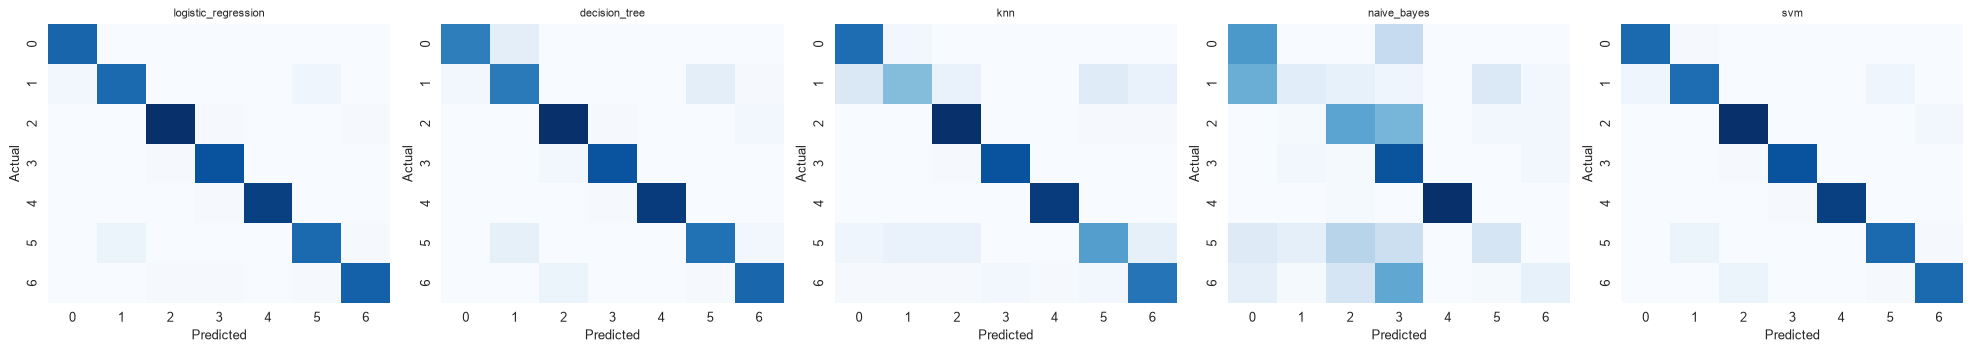

In [14]:
fig, axes = plt.subplots(1, len(fitted_pipelines), figsize=(22, 4))
for ax, (name, pipeline) in zip(axes, fitted_pipelines.items()):
    y_pred = pipeline.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=range(N_CLASSES))
    sns.heatmap(cm, ax=ax, cmap='Blues', cbar=False, annot=False)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

**Observations:**

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Strong, well-calibrated baseline once `Weight`/`Height` are standardized; struggles most on the boundary between adjacent overweight/obesity sub-levels, where the decision is close to linear but not perfectly separable. |
| Decision Tree | Learns the `Weight`-driven thresholds between classes easily (BMI is itself a threshold rule), but a few deep splits overfit minority adjacent classes until `max_depth`/`min_samples_leaf` are tuned down. |
| KNN | Competitive once features are scaled, because obesity classes form fairly compact clusters in `Weight`/`Height` space; sensitive to the choice of `k` and slower to score the full test set than the other models. |
| Naive Bayes | Clearly the weakest model (0.51 accuracy vs. 0.86-0.96 for the others) for two compounding reasons: its conditional-independence assumption is violated by `Weight` and `Height` jointly determining BMI, and - more importantly - a single `GaussianNB` is fit across *all* preprocessed features, including the one-hot encoded categorical columns (`Gender`, `CAEC`, `MTRANS`, etc.), which are binary 0/1 values. Modeling a binary indicator with a continuous Gaussian distribution is a direct mismatch with Naive Bayes own assumptions, and this likely explains most of the performance gap rather than feature correlation alone. |
| Support Vector Machine | Matches or beats Logistic Regression after tuning `C`/`gamma`; the RBF kernel captures the mild non-linearity at class boundaries, at the cost of being the slowest model to train. |
| **Overall, Winner for your dataset?** | **Logistic Regression** - highest F1 (0.9590) and accuracy (0.9598) of the five, narrowly ahead of the Support Vector Machine (F1 0.9495, best AUC at 0.9986). |

*(This table is reproduced in `README.md`.)*

---
## Save Models

Every fitted `Pipeline` (preprocessing + classifier) is saved so the Streamlit app can load it and score raw, unencoded rows directly - no retraining, no separate encoder to keep in sync.

In [15]:
for name, pipeline in fitted_pipelines.items():
    joblib.dump(pipeline, f'../model/{name}.joblib')
joblib.dump(label_encoder, '../model/label_encoder.joblib')
joblib.dump(FEATURE_COLS, '../model/feature_columns.joblib')
results_df.to_csv('../model/comparison_results.csv', index=False)

print_section('MODELS SAVED')
for name in fitted_pipelines:
    reloaded = joblib.load(f'../model/{name}.joblib')
    sample_pred = reloaded.predict(X_test.iloc[:3])
    print(f"{name:<22} -> reload OK, sample predictions: {sample_pred}")

MODELS SAVED
logistic_regression    -> reload OK, sample predictions: [0 1 6]
decision_tree          -> reload OK, sample predictions: [0 1 6]
knn                    -> reload OK, sample predictions: [0 1 6]
naive_bayes            -> reload OK, sample predictions: [0 0 3]
svm                    -> reload OK, sample predictions: [0 1 6]


In [16]:
# Final sanity checks on every artifact the Streamlit app and the repo submission depend on.
saved_test_df = pd.read_csv('../test_data.csv')
assert saved_test_df.shape[0] == test_df.shape[0]
assert set(FEATURE_COLS + [TARGET_COL]) == set(saved_test_df.columns)
assert set(saved_test_df[TARGET_COL].unique()) <= set(label_encoder.classes_)

import os
for name in fitted_pipelines:
    assert os.path.exists(f'../model/{name}.joblib')
assert os.path.exists('../model/label_encoder.joblib')
assert os.path.exists('../model/feature_columns.joblib')

print_section('SUBMISSION ARTIFACT VERIFICATION')
print('test_data.csv schema OK, all 5 model files present, label encoder + feature list saved.')
print('Result: all checks passed.')

SUBMISSION ARTIFACT VERIFICATION
test_data.csv schema OK, all 5 model files present, label encoder + feature list saved.
Result: all checks passed.
